# Earth-to-Mars Planner

In [70]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:
import numpy as np
from numpy.linalg import norm
from tqdm import tqdm
import plotly.graph_objects as go

from cesium.math.rotations import wrap_to_2pi, wrap_to_pi, dcm_x, dcm_z
from cesium.math.time import greg_to_jd, jd_to_greg
from cesium.orbital.ephemeris import planet_elements_and_rv
from cesium.orbital.transformations import ECI_from_HCI
from cesium.orbital.porkchop import plot_porkchop
from cesium.world.constants import MU_SUN
from cesium.constants import C_LIGHT, DAY_TO_SEC, RAD_TO_DEG, M_TO_KM
from lamberthub import izzo2015


## Time grid for intercept
From wikipedia, around 2035-2036 is optimal:
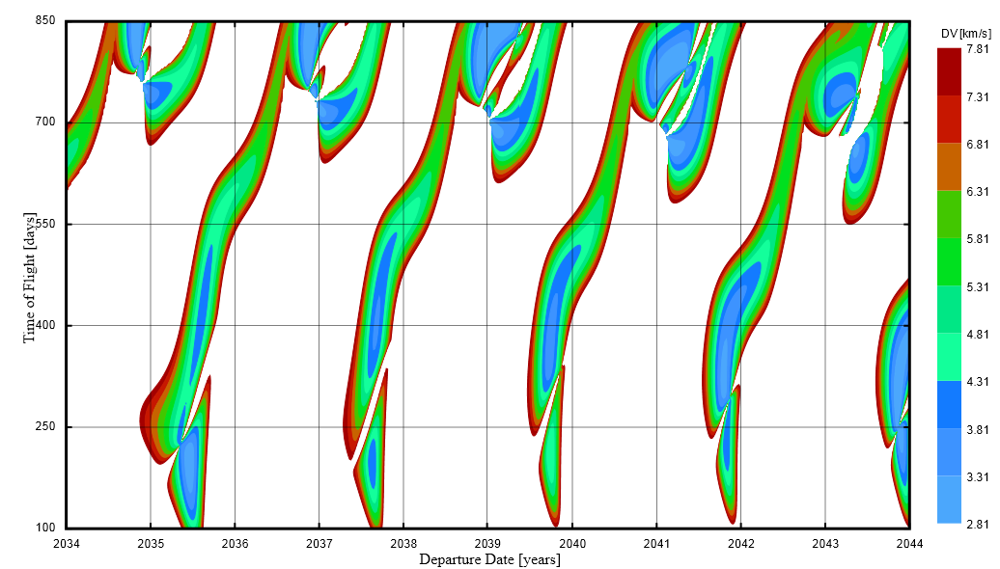

In [72]:
t_dep_jd = np.arange(greg_to_jd(2043,6,0,0,0,0), greg_to_jd(2044,6,0,0,0,0))
t_arr_jd = np.arange(greg_to_jd(2043,6,0,0,0,0) + 100, greg_to_jd(2044,6,0,0,0,0) + 300)
N_DEP = len(t_dep_jd)
N_ARR = len(t_arr_jd)
print(f"Search space length: ({N_DEP},{N_ARR})")


t_tot_jd = np.sort(np.concatenate((t_dep_jd, t_arr_jd)))

dep_grid_jd, arr_grid_jd = np.meshgrid(
    t_dep_jd,
    t_arr_jd,
    indexing="ij"
)
tof_grid_jd = arr_grid_jd - dep_grid_jd

Search space length: (366,566)


## Calculate characteristics

In [73]:
rv_dep_earth_hci = np.array([np.ravel(planet_elements_and_rv(3, t)[1:]) for t in t_dep_jd])
rv_arr_mars_hci = np.array([np.ravel(planet_elements_and_rv(4, t)[1:]) for t in t_arr_jd])

dcm_eci_wrt_hci = ECI_from_HCI()

In [74]:
def departure_characteristics(v_dep_eci: np.ndarray):
    C3 = norm(v_dep_eci)**2
    rla = wrap_to_2pi(np.arctan2(v_dep_eci[1], v_dep_eci[0]))
    dla = wrap_to_pi(np.arcsin(v_dep_eci[2] / norm(v_dep_eci)))
    return C3, rla, dla

def calc_transfer(r1_intrl: np.ndarray, r2_intrl: np.ndarray, tof_s: float, mu = MU_SUN):
    # Time and speed of light check
    if tof_s <= 0 or (norm(r1_intrl - r2_intrl) / tof_s) > C_LIGHT:
        return np.nan, np.nan

    result = izzo2015(mu, r1_intrl, r2_intrl, float(tof_s), M=0)
    v1_intrl, v2_intrl = np.array(result[0]).reshape((3,)), np.array(result[1]).reshape((3,))

    
    velocities = np.concatenate((v1_intrl, v2_intrl))
    if not np.all(np.isfinite(velocities)):
        raise ValueError("Lambert returned non-finite velocities")
    # Could be numerical, so "real" it out
    imag_max = np.max(np.abs(velocities.imag))
    if imag_max > 1e-9:
        raise ValueError(f"Lambert returned complex velocities: max |imag| = {imag_max:.3g} km/s")

    return v1_intrl.real, v2_intrl.real

In [75]:
C3_grid_km2 = np.full((N_DEP, N_ARR), np.nan)
rla_grid = np.full((N_DEP, N_ARR), np.nan)
dla_grid = np.full((N_DEP, N_ARR), np.nan)
dv_tot = np.full((N_DEP, N_ARR, 3), np.nan)
v_dep_hci_km = np.full((N_DEP, N_ARR, 3), np.nan)
v_arr_hci_km = np.full((N_DEP, N_ARR, 3), np.nan)

v1_hci_grid_km = np.full((N_DEP, N_ARR, 3), np.nan)
v2_hci_grid_km = np.full((N_DEP, N_ARR, 3), np.nan)

failed_transfers = []
for dep_i in tqdm(range(N_DEP)):
    rv_dep = rv_dep_earth_hci[dep_i]
    for arr_i in range(N_ARR):
        rv_arr = rv_arr_mars_hci[arr_i]
        tof_jd = tof_grid_jd[dep_i, arr_i]
        try:
            v1, v2 = calc_transfer(rv_dep[:3], rv_arr[:3], tof_jd * DAY_TO_SEC)
        except ValueError as e:
            failed_transfers.append((t_dep_jd[dep_i], t_arr_jd[arr_i], str(e)))
            print(f"Failed transfer: departure JD {t_dep_jd[dep_i]}, arrival JD {t_arr_jd[arr_i]}: {e}")
            continue

        v1_hci = v1 - rv_dep[3:6]  # Earth-relative, expressed in HCI axes
        v2_hci = v2 - rv_arr[3:6]  # Mars-relative, expressed in HCI axes
        v1_eci = dcm_eci_wrt_hci @ v1_hci
        C3, rla, dla = departure_characteristics(v1_eci)
        
        C3_grid_km2[dep_i, arr_i] = C3 * M_TO_KM*M_TO_KM
        rla_grid[dep_i, arr_i] = rla * RAD_TO_DEG
        dla_grid[dep_i, arr_i] = dla * RAD_TO_DEG
        v_dep_hci_km[dep_i, arr_i] = v1_hci * M_TO_KM
        v_arr_hci_km[dep_i, arr_i] = v2_hci * M_TO_KM
        v1_hci_grid_km[dep_i, arr_i] = v1 * M_TO_KM
        v2_hci_grid_km[dep_i, arr_i] = v2 * M_TO_KM

print(f"{len(failed_transfers)} failed transfers; see failed_transfers for dates and errors.")


100%|██████████| 366/366 [00:06<00:00, 60.49it/s]

0 failed transfers; see failed_transfers for dates and errors.


## Plots

In [ ]:
common_options = {
    "xlabel": "Earth departure [JD]",
    "ylabel": "Time-of-flight [day]",
    "xaxis": "gregorian",      
    "yaxis": "time-of-flight", 
    "show": True,
}

In [106]:
fig = plot_porkchop(
    t_dep_jd, t_arr_jd, C3_grid_km2,
    # zmin=0, zmax=100,
    contour_min=0, contour_max=40, contour_step=2,
    title="Earth-to-Mars departure C3",
    zlabel="C3 [km²/s²]",
    **common_options
)

In [107]:
fig = plot_porkchop(
    t_dep_jd, t_arr_jd - t_dep_jd[0], dla_grid,
    # zmin=0, zmax=100,
    contour_min=-40, contour_max=40, contour_step=2,
    title="Earth-to-Mars Declination",
    xlabel="Earth departure [JD]", ylabel="Time-of-flight [day]",
    zlabel="Declination [º]",
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>DLA: %{z:.2f}º<extra></extra>",
    xaxis="gregorian",      
    yaxis="time-of-flight", 
    show=True,
)

In [108]:
v_dep_hci_km_norm = norm(v_dep_hci_km, axis=2)
v_arr_hci_km_norm = norm(v_arr_hci_km, axis=2)

fig = plot_porkchop(
    t_dep_jd, t_arr_jd - t_dep_jd[0], v_arr_hci_km_norm,
    # zmin=0, zmax=100,
    contour_min=0, contour_max=10, contour_step=1,
    title="Earth-to-Mars Arrival Excess Speed",
    xlabel="Earth departure [JD]", ylabel="Time-of-flight [day]",
    zlabel="V_arr_inf in HCI [km/s]",
    show=True,
)

## Constraints

In [89]:
ARRIVAL_JD = 2461633
C3_MAX_KM = 15.0  # km/s
DLA_MAX = 33.0  # deg
V_ARR_MAX_KM = 3.5 # km/s



C3_mask = C3_grid_km2.copy()
C3_mask[C3_grid_km2 > C3_MAX_KM] = np.nan
C3_mask[abs(dla_grid) >= DLA_MAX] = np.nan
# C3_mask[v_arr_inf_norm >= V_ARR_MAX] = np.nan


In [90]:
fig = plot_porkchop(
    t_dep_jd, t_arr_jd, C3_mask,
    zmin=0, zmax=C3_MAX_KM,
    contour_min=0, contour_max=C3_MAX_KM, contour_step=0.5,
    title="Earth-to-Mars departure C3 with constraints",
    xlabel="Earth departure [JD]", ylabel="Mars arrival [JD]",
    zlabel="C3 [km²/s²]",
    show=True,
)


## Selecting trajectory